#### Notebook for comparing the cnoidal waves with the waves from the Newton solver, over a range of the elliptic modulus $m$

At fixed $(P,\text{mean})$ the crest elevation determines $m$, with $m\to0$ a cosine-like wave and $m\to1$ the soliton limit.
Instead of choosing amplitudes and reading off $m$, we **choose a grid of $m$ values** and invert the relation to get the crest elevation to give both solvers.
Both solvers then receive identical input $(P,\text{mean},\text{crest})$, so $c$, $B$ and the profile are independent outputs.

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [2]:
from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton
from camera.pdeCamera import KdV
from solvers.help import *
from waves.soliton import kdv_cnoidal


import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.special import ellipj, ellipk, ellipe
from scipy.optimize import brentq

### From $m$ to the crest elevation

With $\kappa=2K(m)/P$, $b=2m\kappa^2$ and $q=\big(E(m)-(1-m)K(m)\big)/(mK(m))$ (the mean of $\mathrm{cn}^2$), the wave is $\phi=a+b\,\mathrm{cn}^2$ with $a=\text{mean}-bq$.
The crest is $\phi(0)=a+b$, so

$$
\text{crest}-\text{mean}=b(m)\,\big(1-q(m)\big).
$$

This is the same relation that `kdv_cnoidal` inverts with `brentq`. Here we evaluate it in the forward direction, and then check that `kdv_cnoidal` returns the $m$ we started from.

In [3]:
# Wave parameters
P    = 16
N    = 2**7
mean = 0.0
c1   = Camera(P, N, 1)

def crest_of_m(m, P=P, mean=mean):
    '''Crest elevation (above the mean) of the cnoidal wave with parameter m.'''
    K, E  = ellipk(m), ellipe(m)
    kappa = 2*K/P
    b     = 2*m*kappa**2
    q     = (E - (1-m)*K)/(m*K)
    return mean + b*(1-q)

# the portion of (0,1) that we cover
m_grid = np.array([1e-3, 1e-2, 0.1, 0.3, 0.5, 0.7, 0.9, 0.99, 0.999])
pd.DataFrame({"m": m_grid, "crest": crest_of_m(m_grid)}).to_string(index=False, float_format=lambda v: f"{v:.4e}")

'         m      crest\n1.0000e-03 3.8577e-05\n1.0000e-02 3.8796e-04\n1.0000e-01 4.1159e-03\n3.0000e-01 1.4382e-02\n5.0000e-01 2.9169e-02\n7.0000e-01 5.4069e-02\n9.0000e-01 1.1870e-01\n9.9000e-01 3.0947e-01\n9.9900e-01 5.8078e-01'

### One comparison

`compare` solves the Newton problem for the crest that belongs to $m$, builds the cnoidal wave for the same crest, and returns everything needed for the plots.
`phi_hat_mid` is the Newton spectrum shifted by half a period, so that the crest sits at $x=0$ on the camera grid, as for the cnoidal wave.

In [4]:
def compare(m_target, P=P, N=N, mean=mean, n_steps=50):
    cam   = Camera(P, N, 1)
    crest = crest_of_m(m_target, P, mean)

    wp = KdVNewton(P, crest, mean, cam)
    wp.solve_w_continuation(n_steps=n_steps)
    phi_newton = wp.get_physical(wp.phi_hat_mid)

    phi_cn, c_cn, m = kdv_cnoidal(P=P, crest=crest, mean=mean, x=cam.x, t=0)
    phi_cn = phi_cn[0]

    return dict(
        m_target=m_target, m=m, crest=crest, cam=cam, wp=wp,
        phi_newton=phi_newton, phi_cn=phi_cn, c_newton=wp.c, c_cn=c_cn,
        err_max=np.max(np.abs(phi_newton - phi_cn)),
        err_rms=np.sqrt(np.mean((phi_newton - phi_cn)**2)),
        err_c=abs(wp.c - c_cn),
    )

r = compare(0.9)
print(f"target m = {r['m_target']},  m returned by kdv_cnoidal = {r['m']:.10f}")
print(f"Newton wave speed:    {r['c_newton']:.10f}")
print(f"Cnoidal wave speed:   {r['c_cn']:.10f}")
print(f"Maximum profile error: {r['err_max']:.3e}")
print(f"RMS profile error:     {r['err_rms']:.3e}")

target m = 0.9,  m returned by kdv_cnoidal = 0.9000000000
Newton wave speed:    0.9871518934
Cnoidal wave speed:   0.9871518934
Maximum profile error: 1.110e-16
RMS profile error:     4.332e-17


### Profiles for four values of $m$

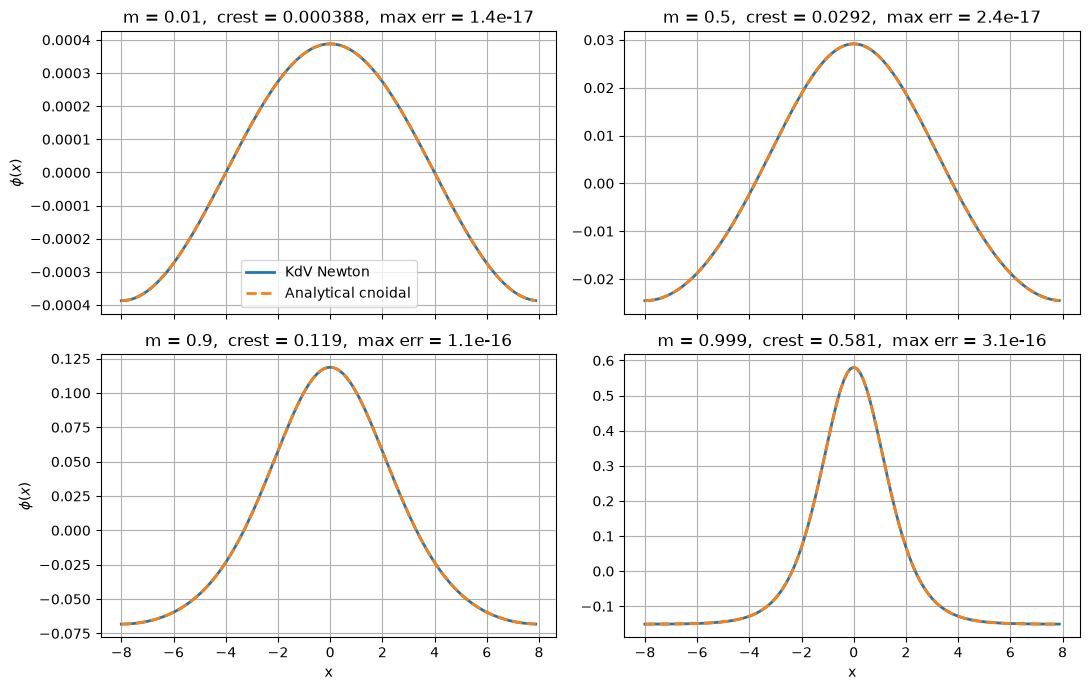

In [5]:
m_show = [0.01, 0.5, 0.9, 0.999]
res = {m: compare(m) for m in m_show}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, m in zip(axes.ravel(), m_show):
    r = res[m]
    ax.plot(r["cam"].x, r["phi_newton"], label="KdV Newton", linewidth=2)
    ax.plot(r["cam"].x, r["phi_cn"], "--", label="Analytical cnoidal", linewidth=2)
    ax.set_title(f"m = {m},  crest = {r['crest']:.3g},  max err = {r['err_max']:.1e}")
    ax.grid(True)
axes[0, 0].legend()
for ax in axes[1]: ax.set_xlabel("x")
for ax in axes[:, 0]: ax.set_ylabel(r"$\phi(x)$")
plt.tight_layout(); plt.show()

### Error profiles and spectra

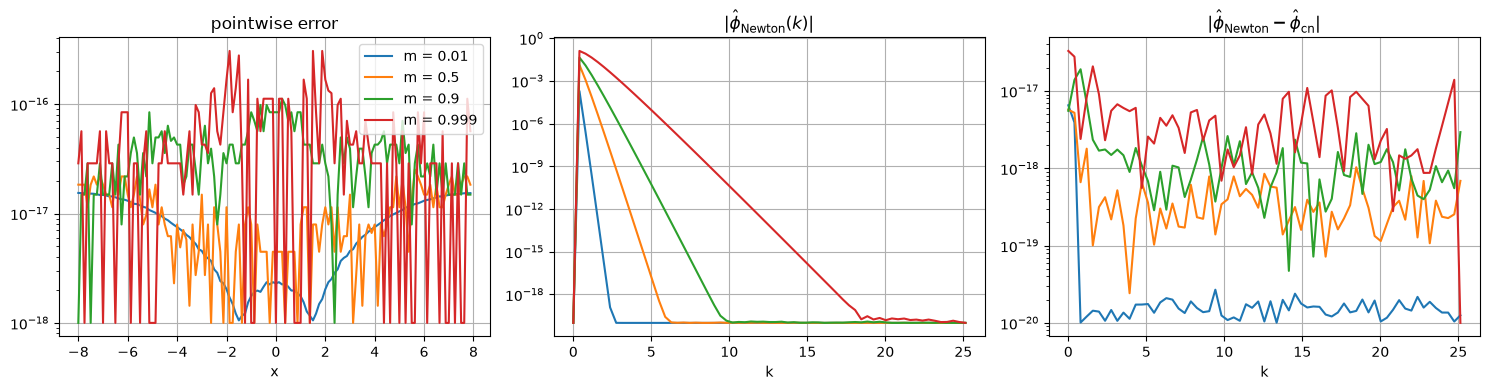

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for m in m_show:
    r = res[m]
    k_r = 2*np.pi*np.fft.rfftfreq(N, d=r["cam"].dx)
    cn_hat = np.fft.rfft(r["phi_cn"])/N
    nw_hat = r["wp"].phi_hat_mid

    axes[0].semilogy(r["cam"].x, np.abs(r["phi_newton"] - r["phi_cn"]) + 1e-18, label=f"m = {m}")
    axes[1].semilogy(k_r, np.abs(nw_hat) + 1e-20, label=f"m = {m}")
    axes[2].semilogy(k_r, np.abs(nw_hat - cn_hat) + 1e-20, label=f"m = {m}")

axes[0].set_title("pointwise error"); axes[0].set_xlabel("x")
axes[1].set_title(r"$|\hat\phi_{\rm Newton}(k)|$"); axes[1].set_xlabel("k")
axes[2].set_title(r"$|\hat\phi_{\rm Newton}-\hat\phi_{\rm cn}|$"); axes[2].set_xlabel("k")
axes[0].legend()
for a in axes: a.grid(True)
plt.tight_layout(); plt.show()

### Error against $m$ (fixed $N$)

The profile error should be flat at the level set by the Newton tolerance as long as the spectrum is resolved. The spectrum is least resolved near $m\to1$, so that is where a failure would appear first.

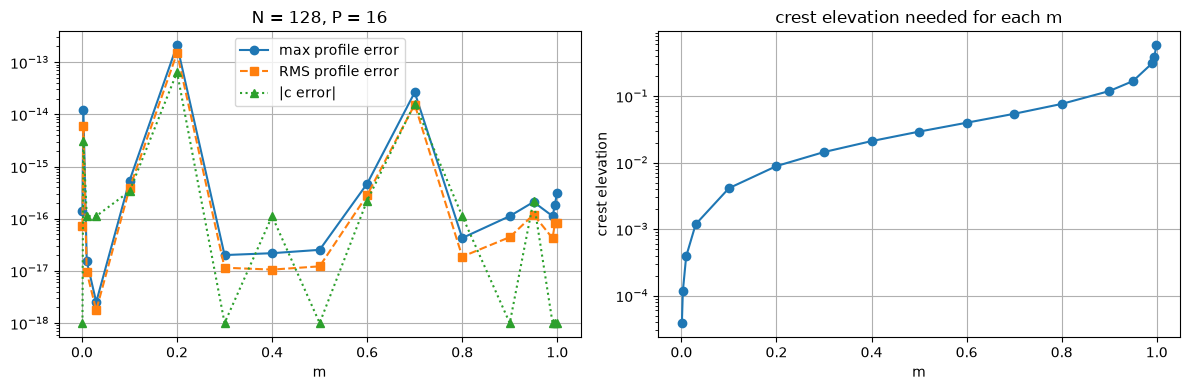

        m     crest   max_err   rms_err     c_err  m_mismatch
1.000e-03 3.858e-05 1.413e-16 7.204e-17 0.000e+00   2.825e-16
3.000e-03 1.159e-04 1.221e-14 6.023e-15 3.109e-15   2.381e-16
1.000e-02 3.880e-04 1.442e-17 8.546e-18 1.110e-16   1.735e-17
3.000e-02 1.179e-03 1.518e-18 7.566e-19 1.110e-16   4.094e-16
1.000e-01 4.116e-03 5.321e-16 3.786e-16 3.331e-16   3.608e-16
2.000e-01 8.847e-03 2.109e-13 1.494e-13 6.406e-14   4.718e-16
3.000e-01 1.438e-02 1.908e-17 1.049e-17 0.000e+00   5.551e-16
4.000e-01 2.100e-02 2.082e-17 9.576e-18 1.110e-16   5.551e-17
5.000e-01 2.917e-02 2.429e-17 1.121e-17 0.000e+00   0.000e+00
6.000e-01 3.967e-02 4.684e-16 2.819e-16 2.220e-16   1.110e-16
7.000e-01 5.407e-02 2.638e-14 1.542e-14 1.610e-14   1.110e-16
8.000e-01 7.609e-02 4.163e-17 1.773e-17 1.110e-16   0.000e+00
9.000e-01 1.187e-01 1.110e-16 4.332e-17 0.000e+00   1.110e-16
9.500e-01 1.679e-01 2.082e-16 1.188e-16 2.220e-16   0.000e+00
9.900e-01 3.095e-01 1.110e-16 4.115e-17 0.000e+00   0.000e+00
9.950e-0

In [7]:
m_sweep = np.concatenate([[1e-3, 3e-3, 1e-2, 3e-2], np.linspace(0.1, 0.9, 9), [0.95, 0.99, 0.995, 0.999]])
rows = []
for m in m_sweep:
    r = compare(m)
    rows.append((m, r["crest"], r["err_max"], r["err_rms"], r["err_c"], abs(r["m"]-m)))
df = pd.DataFrame(rows, columns=["m", "crest", "max_err", "rms_err", "c_err", "m_mismatch"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(df.m, df.max_err + 1e-18, "o-", label="max profile error")
axes[0].semilogy(df.m, df.rms_err + 1e-18, "s--", label="RMS profile error")
axes[0].semilogy(df.m, df.c_err + 1e-18, "^:", label="|c error|")
axes[0].set_xlabel("m"); axes[0].legend(); axes[0].grid(True)
axes[0].set_title(f"N = {N}, P = {P}")

axes[1].semilogy(df.m, df.crest, "o-")
axes[1].set_xlabel("m"); axes[1].set_ylabel("crest elevation"); axes[1].grid(True)
axes[1].set_title("crest elevation needed for each m")
plt.tight_layout(); plt.show()
print(df.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

### Error against $N$

Convergence in the number of modes. The error should fall spectrally until it reaches the plateau set by the Newton tolerance (`tol = 1e-13`), after which increasing $N$ does not help.
Modes that are too few for the sharpest waves may make Newton fail, which is recorded as a missing point.

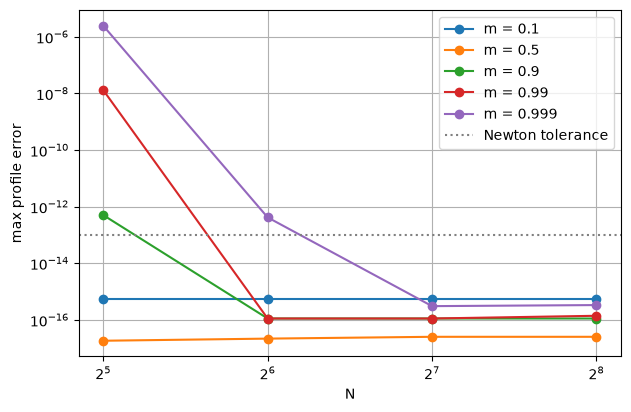

'       0.100    0.500    0.900    0.990    0.999\n32  5.32e-16 1.73e-17 5.03e-13 1.31e-08 2.46e-06\n64  5.32e-16 2.08e-17 1.11e-16 1.11e-16 4.17e-13\n128 5.32e-16 2.43e-17 1.11e-16 1.11e-16 3.05e-16\n256 5.32e-16 2.43e-17 1.11e-16 1.39e-16 3.33e-16'

In [8]:
N_list = [2**5, 2**6, 2**7, 2**8]
m_N    = [0.1, 0.5, 0.9, 0.99, 0.999]
err_N  = {m: [] for m in m_N}
for m in m_N:
    for n in N_list:
        try:
            err_N[m].append(compare(m, N=n)["err_max"])
        except Exception as e:
            err_N[m].append(np.nan)

fig, ax = plt.subplots(figsize=(7, 4.5))
for m in m_N:
    ax.semilogy(N_list, np.array(err_N[m]) + 1e-18, "o-", label=f"m = {m}")
ax.set_xscale("log", base=2); ax.set_xlabel("N"); ax.set_ylabel("max profile error")
ax.axhline(1e-13, color="gray", ls=":", label="Newton tolerance")
ax.legend(); ax.grid(True); plt.show()
pd.DataFrame(err_N, index=N_list).to_string(float_format=lambda v: f"{v:.2e}")